In [3]:
from google.colab import files
uploaded = files.upload()


Saving energy_small.csv to energy_small.csv


In [4]:
import pandas as pd

df = pd.read_csv('energy_small.csv')
df.head()


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.0


In [5]:
df['Global_active_power'] = pd.to_numeric(df['Global_active_power'], errors='coerce')
df['Global_intensity'] = pd.to_numeric(df['Global_intensity'], errors='coerce')
df['Voltage'] = pd.to_numeric(df['Voltage'], errors='coerce')
df['Sub_metering_1'] = pd.to_numeric(df['Sub_metering_1'], errors='coerce')
df['Sub_metering_2'] = pd.to_numeric(df['Sub_metering_2'], errors='coerce')
df['Sub_metering_3'] = pd.to_numeric(df['Sub_metering_3'], errors='coerce')

df.dropna(inplace=True)


In [6]:
threshold = df['Global_active_power'].quantile(0.75)
df['HighConsumption'] = (df['Global_active_power'] > threshold).astype(int)

threshold


np.float64(2.5614999999999997)

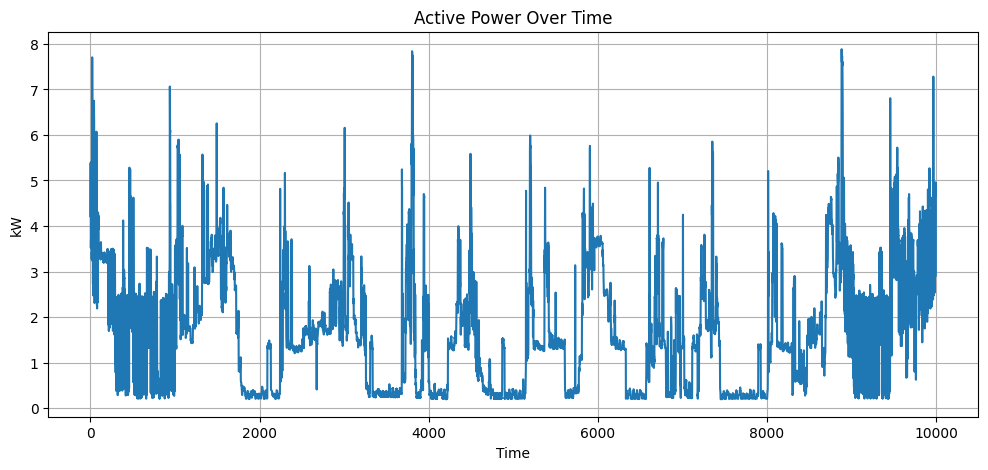

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))
plt.plot(df['Global_active_power'])
plt.title('Active Power Over Time')
plt.xlabel('Time')
plt.ylabel('kW')
plt.grid(True)
plt.show()


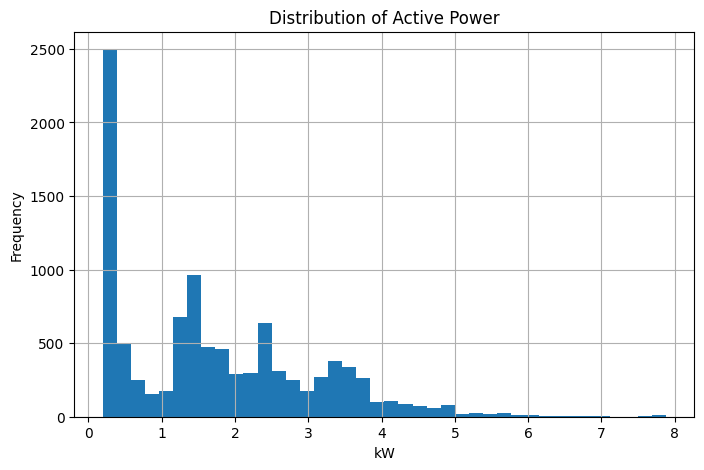

In [8]:
df['Global_active_power'].hist(bins=40, figsize=(8,5))
plt.title('Distribution of Active Power')
plt.xlabel('kW')
plt.ylabel('Frequency')
plt.show()


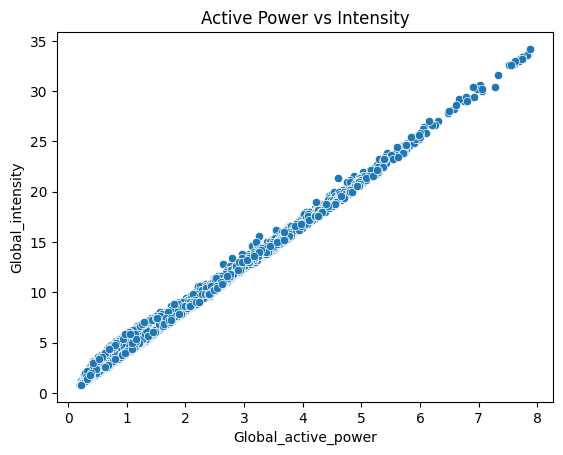

In [9]:
import seaborn as sns

sns.scatterplot(x=df['Global_active_power'], y=df['Global_intensity'])
plt.title('Active Power vs Intensity')
plt.show()


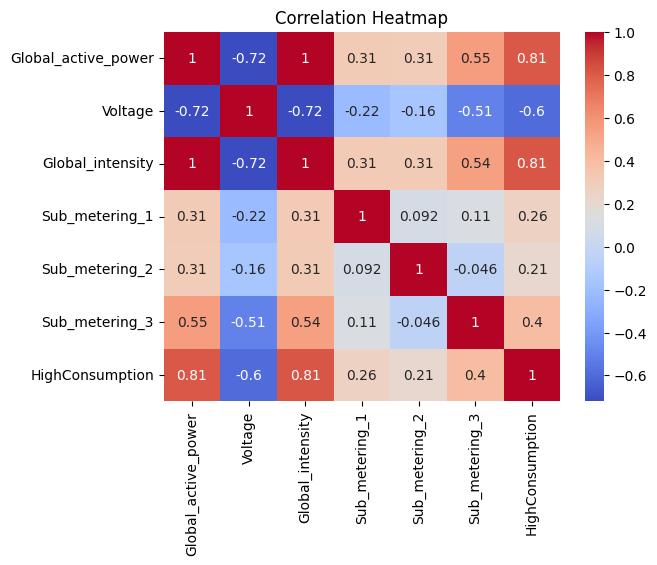

In [12]:
numeric_df = df.select_dtypes(include=['float64', 'int64'])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()


Logistic Regression Accuracy: 0.9935
[[1499    4]
 [   9  488]]
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      1503
           1       0.99      0.98      0.99       497

    accuracy                           0.99      2000
   macro avg       0.99      0.99      0.99      2000
weighted avg       0.99      0.99      0.99      2000

Random Forest Accuracy: 1.0
[[1503    0]
 [   0  497]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1503
           1       1.00      1.00      1.00       497

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



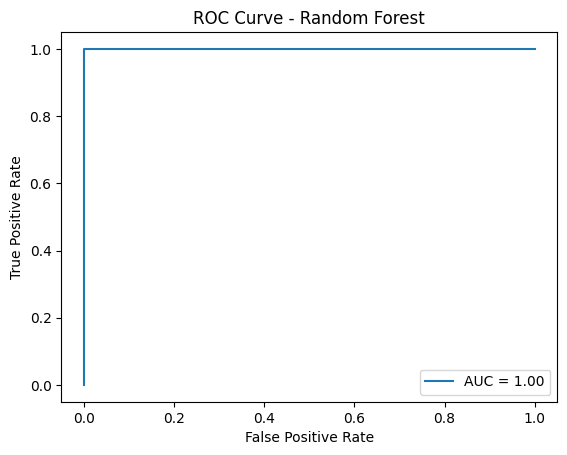

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, auc
import matplotlib.pyplot as plt

# آماده‌سازی داده‌ها
X = df[['Global_active_power','Global_intensity','Voltage','Sub_metering_1','Sub_metering_2','Sub_metering_3']]
y = df['HighConsumption']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Logistic Regression
lr = LogisticRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_lr))
print(confusion_matrix(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))

# Random Forest
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print(confusion_matrix(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

# ROC Curve
y_prob = rf.predict_proba(X_test)[:,1]
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.2f}')
plt.title('ROC Curve - Random Forest')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()
